# Estágio 02 — Precipitação (Open-Meteo)

Puxa precipitação horária da API Open-Meteo para cada estação, no período coberto pelos caudalímetros.

**Entrada:** `data/interim/<estação>_merged.csv` (só para descobrir o intervalo de datas)

**Saída** (em `data/interim/`):

| Ficheiro | Para quê |
|---|---|
| `<estação>_precipitacao.csv` | série horária (`datetime`, `station`, `precip_mm`, `source`) para juntar depois com o caudal |

**Regras deste estágio:**

- a fonte é só a Open-Meteo (archive para o passado, forecast para hoje / futuro);
- o fuso é `Europe/Lisbon`, o mesmo dos exports NIVUS, para a junção posterior ser directa;
- valores nulos da API entram como 0 mm.

In [29]:
from datetime import date, datetime, timedelta
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import pandas as pd
import requests

from pipeline_config import (
    FIGURES_DIR,
    INTERIM_DIR,
    OPEN_METEO_ARCHIVE_URL,
    OPEN_METEO_FORECAST_URL,
    OPEN_METEO_TIMEZONE,
    STATIONS,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

for directory in (INTERIM_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("saída:    ", INTERIM_DIR)
print("fuso:     ", OPEN_METEO_TIMEZONE)
print("estações: ", ", ".join(STATIONS))

saída:     /Users/marcosgrandesso/wada/afluencia_indevida_pipeline/data/interim
fuso:      Europe/Lisbon
estações:  ameal, antanhol


## 1. Período a pedir

O intervalo sai dos CSVs do merge: um dia de calendário extra no início e no fim, para a chuva imediatamente à volta das primeiras e últimas amostras não ficar de fora.

In [30]:
def caudal_date_range(slug: str) -> tuple[date, date]:
    path = INTERIM_DIR / f"{slug}_merged.csv"
    frame = pd.read_csv(path, usecols=["datetime"], parse_dates=["datetime"])
    start = frame["datetime"].min().date() - timedelta(days=1)
    end = frame["datetime"].max().date() + timedelta(days=1)
    return start, end


station_windows = {}
for slug in STATIONS:
    start, end = caudal_date_range(slug)
    station_windows[slug] = (start, end)
    print(f"{slug}: {start} → {end}")

ameal: 2025-05-08 → 2026-09-03
antanhol: 2025-05-08 → 2026-09-03


## 2. Pedido à Open-Meteo

A API de arquivo cobre datas passadas; a de forecast cobre hoje e o que ainda não entrou no arquivo. Os dois pedaços são concatenados sem sobreposição.

In [31]:
class OpenMeteoError(Exception):
    """A API devolveu erro, JSON inválido ou ficou inalcançável."""


def _today() -> date:
    return datetime.now(ZoneInfo(OPEN_METEO_TIMEZONE)).date()


def _request_hourly(
    url: str,
    latitude: float,
    longitude: float,
    start_date: date,
    end_date: date,
    source: str,
) -> pd.DataFrame:
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date.isoformat(),
        "end_date": end_date.isoformat(),
        "hourly": "precipitation",
        "timezone": OPEN_METEO_TIMEZONE,
    }
    try:
        response = requests.get(url, params=params, timeout=60)
        response.raise_for_status()
        payload = response.json()
    except requests.RequestException as exc:
        raise OpenMeteoError(f"pedido falhou ({source}): {exc}") from exc

    if payload.get("error"):
        raise OpenMeteoError(f"API error ({source}): {payload.get('reason', 'unknown')}")

    hourly = payload.get("hourly") or {}
    times = hourly.get("time") or []
    values = hourly.get("precipitation") or []
    if len(times) != len(values):
        raise OpenMeteoError(
            f"resposta inconsistente ({source}): {len(times)} horas vs {len(values)} valores"
        )

    return pd.DataFrame(
        {
            "datetime": pd.to_datetime(times),
            "precip_mm": [0.0 if value is None else float(value) for value in values],
            "source": source,
        }
    )


def fetch_hourly_precipitation(
    latitude: float,
    longitude: float,
    start_date: date,
    end_date: date,
) -> pd.DataFrame:
    if start_date > end_date:
        raise ValueError("start_date tem de ser <= end_date")

    today = _today()
    yesterday = today - timedelta(days=1)
    parts = []

    if start_date <= yesterday:
        parts.append(
            _request_hourly(
                OPEN_METEO_ARCHIVE_URL,
                latitude,
                longitude,
                start_date,
                min(end_date, yesterday),
                source="archive",
            )
        )

    if end_date >= today:
        parts.append(
            _request_hourly(
                OPEN_METEO_FORECAST_URL,
                latitude,
                longitude,
                max(start_date, today),
                end_date,
                source="forecast",
            )
        )

    if not parts:
        return pd.DataFrame(columns=["datetime", "precip_mm", "source"])
    return pd.concat(parts, ignore_index=True)


for slug, station in STATIONS.items():
    print(
        f"{slug}: {station['latitude']}, {station['longitude']}"
    )

ameal: 40.185668, -8.547218
antanhol: 40.176601, -8.45903


## 3. Download e gravação

In [32]:
precipitation = {}

for slug, station in STATIONS.items():
    start, end = station_windows[slug]
    frame = fetch_hourly_precipitation(
        station["latitude"],
        station["longitude"],
        start,
        end,
    )
    frame.insert(1, "station", slug)
    frame = frame.sort_values("datetime").drop_duplicates("datetime", keep="last")
    precipitation[slug] = frame.reset_index(drop=True)

    path = INTERIM_DIR / f"{slug}_precipitacao.csv"
    precipitation[slug].to_csv(path, index=False)

    rainy_hours = int((frame["precip_mm"] > 0).sum())
    print(
        f"{slug}: {len(frame):,} horas | "
        f"{frame['precip_mm'].sum():.1f} mm no total | "
        f"{rainy_hours} horas com chuva | "
        f"{path.name}"
    )
    print(f"  {frame['datetime'].min()} → {frame['datetime'].max()}")
    print(f"  fontes: {', '.join(sorted(frame['source'].unique()))}")

ameal: 11,616 horas | 1480.6 mm no total | 1801 horas com chuva | ameal_precipitacao.csv
  2025-05-08 00:00:00 → 2026-09-03 23:00:00
  fontes: archive
antanhol: 11,616 horas | 1569.3 mm no total | 1905 horas com chuva | antanhol_precipitacao.csv
  2025-05-08 00:00:00 → 2026-09-03 23:00:00
  fontes: archive


In [33]:
precipitation["ameal"].head()

,datetime,station,precip_mm,source
0,2025-05-08 00:00:00,ameal,0.0,archive
1,2025-05-08 01:00:00,ameal,0.0,archive
2,2025-05-08 02:00:00,ameal,0.0,archive
3,2025-05-08 03:00:00,ameal,0.0,archive
4,2025-05-08 04:00:00,ameal,0.0,archive


## 4. Totais diários

A série canónica é horária (é a que entra na junção com o caudal). O gráfico mostra o agregado diário, mais fácil de ler.

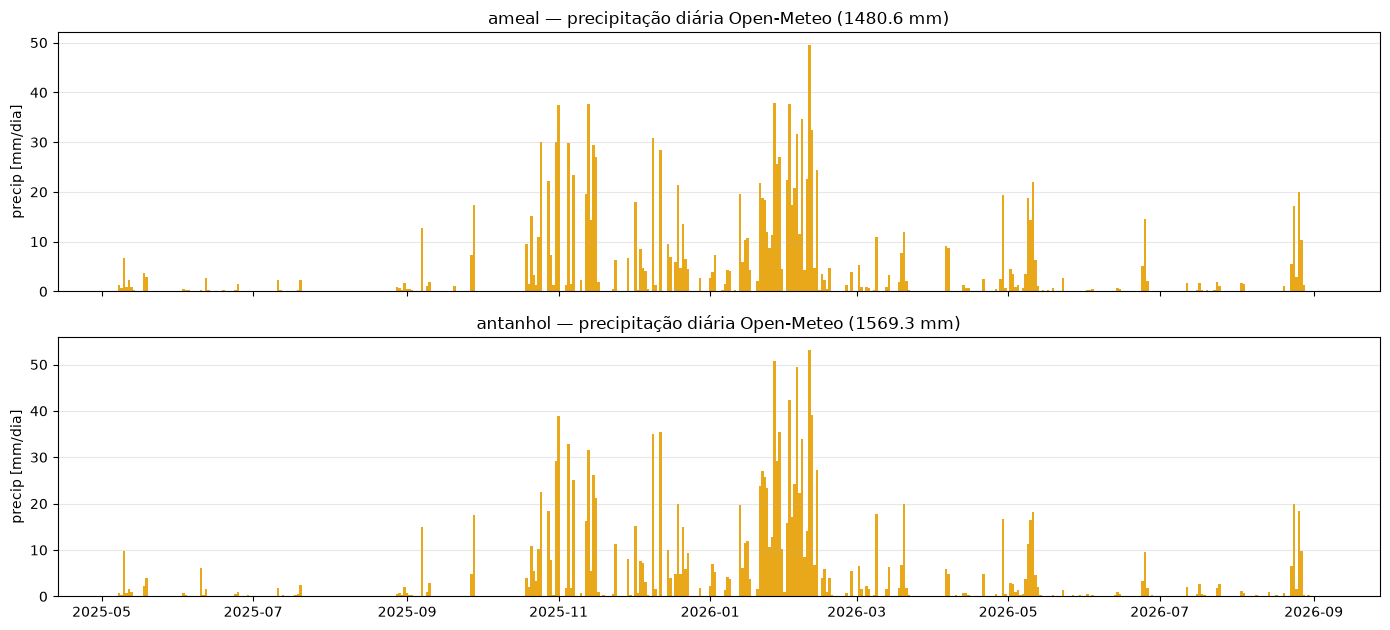

In [34]:
figure, axes = plt.subplots(
    len(precipitation), 1, figsize=(14, 3.2 * len(precipitation)), sharex=True
)
if len(precipitation) == 1:
    axes = [axes]

for axis, (slug, frame) in zip(axes, precipitation.items()):
    daily = frame.set_index("datetime")["precip_mm"].resample("1D").sum()
    axis.bar(daily.index, daily.to_numpy(), width=1.0, color="#e69f00", alpha=0.9)
    axis.set_title(
        f"{slug} — precipitação diária Open-Meteo ({daily.sum():.1f} mm)".replace(",", " ")
    )
    axis.set_ylabel("precip [mm/dia]")
    axis.grid(alpha=0.3, axis="y")

figure.tight_layout()
figure.savefig(FIGURES_DIR / "02_precipitacao.png", dpi=110)
plt.show()

## 5. Precipitação × caudal

Caudal médio diário (linha) e precipitação diária Open-Meteo (barras), no mesmo eixo do tempo. Os buracos do merge aparecem como interrupções na linha.

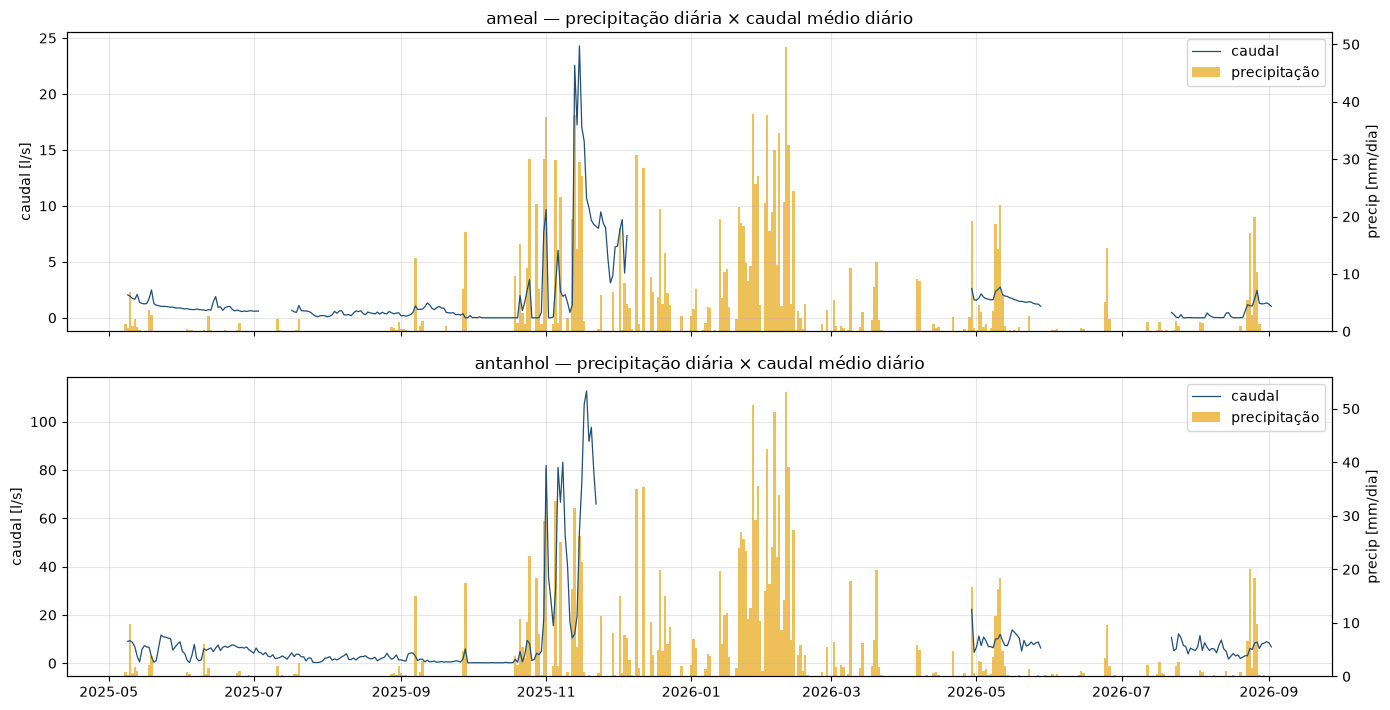

In [ ]:
caudal = {}
for slug in STATIONS:
    caudal[slug] = pd.read_csv(
        INTERIM_DIR / f"{slug}_merged.csv",
        usecols=["datetime", "caudal_l_s"],
        parse_dates=["datetime"],
    )

figure, axes = plt.subplots(
    len(STATIONS), 1, figsize=(14, 3.6 * len(STATIONS)), sharex=True
)
if len(STATIONS) == 1:
    axes = [axes]

for axis, slug in zip(axes, STATIONS):
    precip_daily = precipitation[slug].set_index("datetime")["precip_mm"].resample("1D").sum()
    caudal_daily = caudal[slug].set_index("datetime")["caudal_l_s"].resample("1D").mean()

    axis.plot(
        caudal_daily.index,
        caudal_daily.to_numpy(),
        color="#1f4e79",
        linewidth=0.9,
        label="caudal",
    )
    axis.set_ylabel("caudal [l/s]")
    axis.set_title(f"{slug} — precipitação diária × caudal médio diário")
    axis.grid(alpha=0.3)

    rain = axis.twinx()
    rain.bar(
        precip_daily.index,
        precip_daily.to_numpy(),
        width=1.0,
        color="#e69f00",
        alpha=0.65,
        label="precipitação",
    )
    rain.set_ylabel("precip [mm/dia]")
    # linha de caudal por cima das barras
    axis.set_zorder(rain.get_zorder() + 1)
    axis.patch.set_visible(False)

    handles, labels = axis.get_legend_handles_labels()
    rain_handles, rain_labels = rain.get_legend_handles_labels()
    axis.legend(handles + rain_handles, labels + rain_labels, loc="upper right")

figure.tight_layout()
figure.savefig(FIGURES_DIR / "02_precipitacao_caudal.png", dpi=110)
plt.show()